# FASE 0 (Persiapan)

:0: ENVIRONMENT SETUP (Persiapan Lingkungan)

In [ ]:
# ==============================================================================
# FASE 0: ENVIRONMENT SETUP & GLOBAL IMPORTS
# ==============================================================================
# 1. Mengabaikan Peringatan (Warnings) agar output terminal tetap bersih
import warnings
warnings.filterwarnings('ignore')

# 2. Manajemen Sistem, Waktu, dan File (Python Standard Library)
import os
import time
import random
import gc
import shutil
import glob

# 3. Instalasi & Import Library Eksternal Khusus (Grad-CAM PyTorch)
try:
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image
except ImportError:
    print("⏳ Instalasi library pytorch-grad-cam (Hanya berjalan sekali)...")
    os.system('pip install grad-cam -q')
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image

# 4. Pengolahan Data Matriks, Tabel & Manipulasi Gambar
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

# 5. Visualisasi Data & Grafik (Matplotlib & Seaborn)
import matplotlib.pyplot as plt
import seaborn as sns

# 6. Machine Learning (Scikit-Learn) - Khusus Pemisahan Data & Metrik Evaluasi Akhir
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
from sklearn.preprocessing import label_binarize

# 7. Deep Learning Core (PyTorch & Torchvision)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

print("✅ FASE 0 SELESAI: Semua library berhasil dimuat! Meja operasi siap digunakan.")

⏳ Instalasi library pytorch-grad-cam (Hanya berjalan sekali)...
✅ FASE 0 SELESAI: Semua library berhasil dimuat! Meja operasi siap digunakan.


1: KONFIGURASI GLOBAL (MASTER CONTROL ROOM)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==============================================================================
# FASE 1: KONFIGURASI GLOBAL & HYPERPARAMETER (MASTER CONTROL ROOM)
# ==============================================================================
print("⚙️ MEMUAT KONFIGURASI SISTEM...")

# 1. Reproduksibilitas (Agar hasil AI selalu konsisten setiap di-run)
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

# 2. Deteksi Hardware
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"   -> Hardware Terdeteksi: {DEVICE.type.upper()}")

# 3. Pengaturan Direktori (Paths)
DATASET_PATH = '/content/drive/MyDrive/0.TUGAS AKHIR (TA)/Project hasil/dataset'
BASE_EVIDENCE_DIR  = "./HASIL_PENELITIAN"
DIR_EDA            = os.path.join(BASE_EVIDENCE_DIR, "BUKTI_FISIK_0_EDA")
DIR_SPLIT_UTAMA    = os.path.join(BASE_EVIDENCE_DIR, "BUKTI_FISIK_1_SPLIT_UTAMA")
DIR_SPLIT_SKENARIO = os.path.join(BASE_EVIDENCE_DIR, "BUKTI_FISIK_2_SPLIT_SKENARIO")
DIR_CSV            = os.path.join(BASE_EVIDENCE_DIR, "BUKTI_FISIK_3_CSV")
DIR_VISUAL         = os.path.join(BASE_EVIDENCE_DIR, "BUKTI_FISIK_4_KATALOG_VISUAL")
DIR_TRAINING       = os.path.join(BASE_EVIDENCE_DIR, "BUKTI_FISIK_5_HASIL_TRAINING")

# Eksekusi Pembuatan Laci Folder Fisik
for dir_path in [DIR_EDA, DIR_SPLIT_UTAMA, DIR_SPLIT_SKENARIO, DIR_CSV, DIR_VISUAL, DIR_TRAINING]:
    os.makedirs(dir_path, exist_ok=True)

# 4. Parameter Dataset & Kelas Penyakit (DIPERBAIKI ✅)
CLASSES = ['Normal', 'COVID', 'Pneumonia']
NUM_CLASSES = len(CLASSES)
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
IMG_SIZE_CROP = 224   # Ukuran akhir masuk ke arsitektur DenseNet121
IMG_SIZE_RESIZE = 256 # Ukuran awal sebelum di-crop (untuk ruang augmentasi)

# 5. Skenario Studi Ablasi & Imbalanced Data
PERSENTASE_TOTAL_DATA = 1.0   # Ubah ke 0.3 untuk testing cepat
SKENARIO_RASIO = [5, 10, 20]  # Persentase Data Labeled
SKENARIO_UA = [True, False]   # Uniform Alignment ON/OFF
RETENTION_RATES = {0: 1.0, 1: 0.4, 2: 0.15} # Simulasi Imbalanced
MINIMAL_GAMBAR_PER_KELAS = 3

# 6. Hyperparameter SoftMatch & DenseNet121
TOTAL_EPOCHS = 40
BATCH_SIZE_UNLABELED = 48
LEARNING_RATE = 0.003
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

print("✅ FASE 1 SELESAI: Konfigurasi berhasil dikunci! Lanjut ke Exploratory Data Analysis (EDA).")

⚙️ MEMUAT KONFIGURASI SISTEM...
   -> Hardware Terdeteksi: CUDA
✅ FASE 1 SELESAI: Konfigurasi berhasil dikunci! Lanjut ke Exploratory Data Analysis (EDA).


# FASE 2 (Data Understanding)

SEL 2.1: PEMINDAIAN DATASET (LOGIC/ACTION)

In [ ]:
# ==============================================================================
# FASE 2.1: DATA UNDERSTANDING | PEMINDAIAN DATA (SCANNING)
# ==============================================================================
print("🔍 MEMULAI EKSPLORASI DATA (DATA UNDERSTANDING)...\n")

class_counts = {}
sample_images = {c: [] for c in CLASSES}
all_widths, all_heights, all_modes = [], [], []
total_images = 0

if os.path.exists(DATASET_PATH):
    print("⏳ Sedang memindai seluruh resolusi gambar (Mohon tunggu)...")
    for c in CLASSES:
        class_dir = os.path.join(DATASET_PATH, c)
        if os.path.exists(class_dir):
            files = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            class_counts[c] = len(files)

            # Ambil 3 sampel acak untuk dipajang nanti
            if len(files) > 0:
                sample_images[c] = random.sample(files, min(3, len(files)))

            # Cepat membaca dimensi gambar tanpa memuat seluruh pixel ke RAM
            for f in tqdm(files, desc=f"Scanning {c}", leave=False):
                with Image.open(os.path.join(class_dir, f)) as img:
                    all_widths.append(img.size[0])
                    all_heights.append(img.size[1])
                    all_modes.append(img.mode)
                    total_images += 1
else:
    print(f"❌ ERROR: Folder dataset utama tidak ditemukan! Cek path: {DATASET_PATH}")

print("\n📊 1. RINGKASAN DATASET:")
print("-" * 45)
for c, count in class_counts.items():
    persentase = (count / total_images * 100) if total_images > 0 else 0
    print(f"👉 Kelas {c:<10} : {count} gambar ({persentase:.1f}%)")
print("-" * 45)
print(f"Total Keseluruhan : {total_images} gambar\n")

🔍 MEMULAI EKSPLORASI DATA (DATA UNDERSTANDING)...

⏳ Sedang memindai seluruh resolusi gambar (Mohon tunggu)...



📊 1. RINGKASAN DATASET:
---------------------------------------------
👉 Kelas Normal     : 1802 gambar (34.5%)
👉 Kelas COVID      : 1626 gambar (31.1%)
👉 Kelas Pneumonia  : 1800 gambar (34.4%)
---------------------------------------------
Total Keseluruhan : 5228 gambar



SEL 2.2: PEMBUATAN DASHBOARD EDA (VISUAL/EVIDENCE)

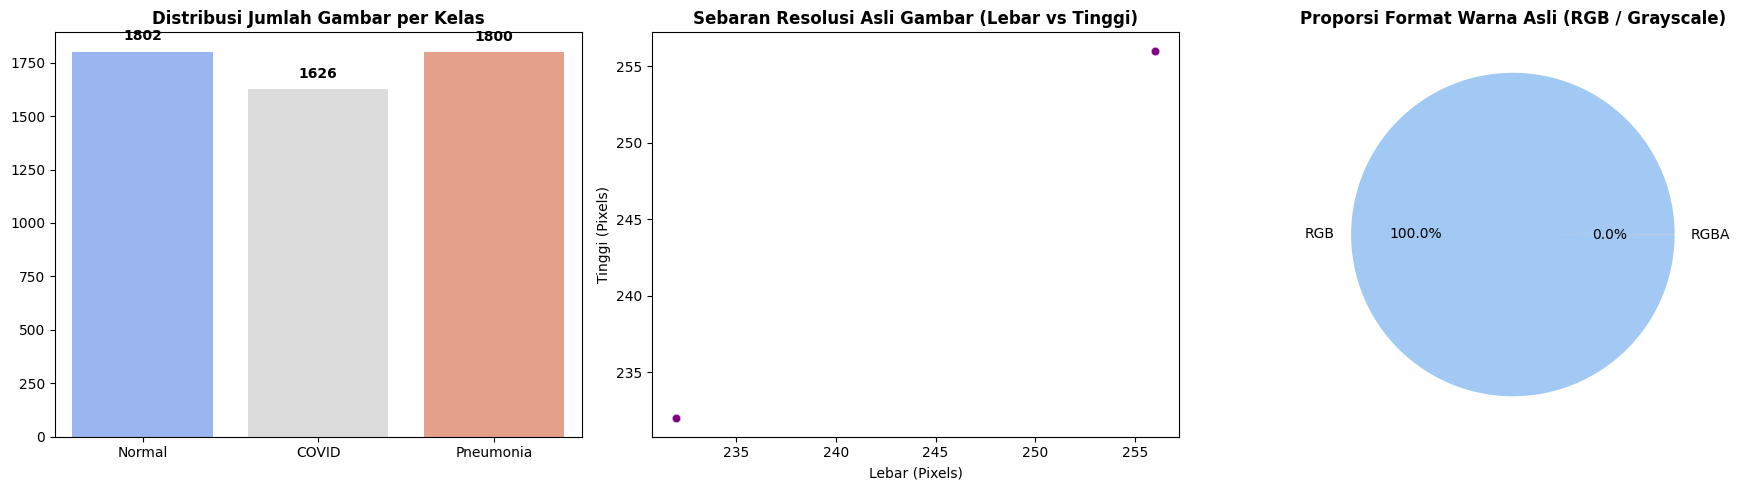


🖼️ 2. ANALISIS VISUAL & HISTOGRAM INTENSITAS PIKSEL:
Grafik bawah menunjukkan sebaran kontras (0=Hitam Gelap, 255=Putih Terang)



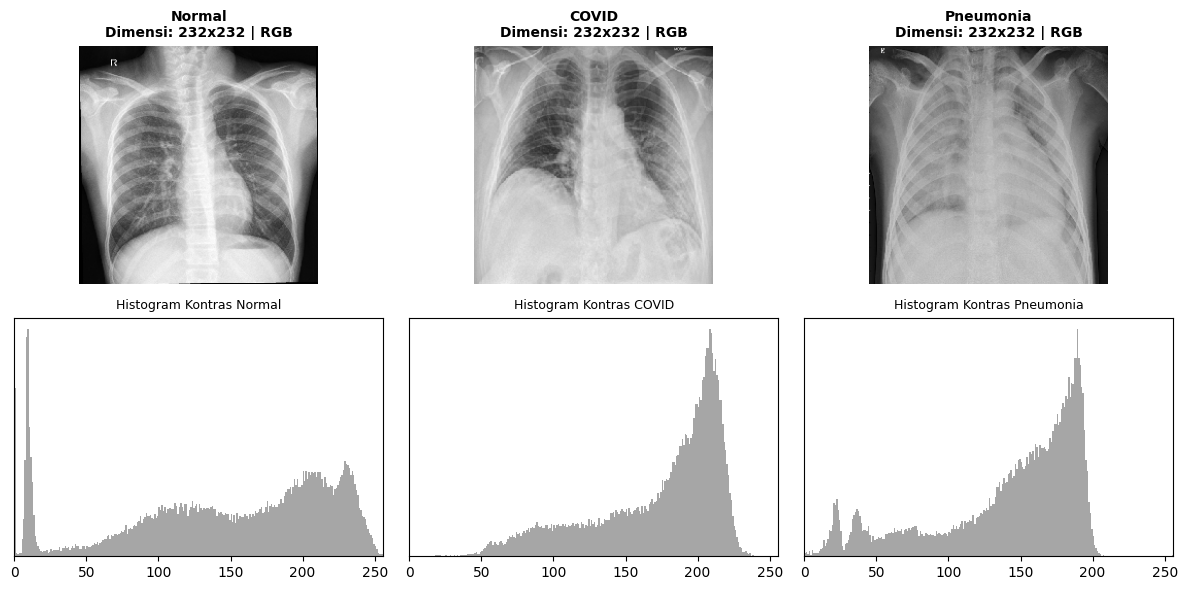


✅ FASE 2 SELESAI: Visualisasi Data Understanding berhasil disimpan di: ./HASIL_PENELITIAN/BUKTI_FISIK_0_EDA


In [ ]:
# ==============================================================================
# FASE 2.2: DATA UNDERSTANDING | VISUALISASI DASHBOARD (EDA)
# ==============================================================================
if total_images > 0:
    # ---------------------------------------------------------
    # A. DASHBOARD DISTRIBUSI KELAS & RESOLUSI
    # ---------------------------------------------------------
    fig = plt.figure(figsize=(18, 5))

    # Grafik 1: Distribusi Kelas
    ax1 = fig.add_subplot(1, 3, 1)
    sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette='coolwarm', ax=ax1)
    ax1.set_title('Distribusi Jumlah Gambar per Kelas', fontweight='bold')
    for i, count in enumerate(class_counts.values()):
        ax1.text(i, count + (total_images*0.01), str(count), ha='center', fontweight='bold')

    # Grafik 2: Scatter Plot Resolusi
    ax2 = fig.add_subplot(1, 3, 2)
    sns.scatterplot(x=all_widths, y=all_heights, alpha=0.5, color='purple', ax=ax2)
    ax2.set_title('Sebaran Resolusi Asli Gambar (Lebar vs Tinggi)', fontweight='bold')
    ax2.set_xlabel('Lebar (Pixels)'); ax2.set_ylabel('Tinggi (Pixels)')

    # Grafik 3: Proporsi Format Warna
    ax3 = fig.add_subplot(1, 3, 3)
    mode_counts = pd.Series(all_modes).value_counts()
    ax3.pie(mode_counts.values, labels=mode_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'))
    ax3.set_title('Proporsi Format Warna Asli (RGB / Grayscale)', fontweight='bold')

    plt.tight_layout()
    save_path_1 = os.path.join(DIR_EDA, '01_Grafik_Distribusi_Dataset.png')
    plt.savefig(save_path_1, dpi=300, bbox_inches='tight')
    plt.show()

    # ---------------------------------------------------------
    # B. ANALISIS HISTOGRAM PIKSEL (PENCAHAYAAN MEDIS)
    # ---------------------------------------------------------
    print("\n🖼️ 2. ANALISIS VISUAL & HISTOGRAM INTENSITAS PIKSEL:")
    print("Grafik bawah menunjukkan sebaran kontras (0=Hitam Gelap, 255=Putih Terang)\n")

    fig2, axes = plt.subplots(2, len(CLASSES), figsize=(12, 6))

    for i, c in enumerate(CLASSES):
        if len(sample_images[c]) > 0:
            img_path = os.path.join(DATASET_PATH, c, sample_images[c][0])
            img = Image.open(img_path)
            img_array = np.array(img.convert('L'))

            axes[0, i].imshow(img, cmap='gray' if img.mode == 'L' else None)
            axes[0, i].set_title(f"{c}\nDimensi: {img.size[0]}x{img.size[1]} | {img.mode}", fontweight='bold', fontsize=10)
            axes[0, i].axis('off')

            axes[1, i].hist(img_array.ravel(), bins=256, range=[0, 256], color='gray', alpha=0.7)
            axes[1, i].set_title(f"Histogram Kontras {c}", fontsize=9)
            axes[1, i].set_xlim([0, 256]); axes[1, i].set_yticks([])

    plt.tight_layout()
    save_path_2 = os.path.join(DIR_EDA, '02_Grafik_Histogram_CXR.png')
    plt.savefig(save_path_2, dpi=300, bbox_inches='tight')
    plt.show()

print(f"\n✅ FASE 2 SELESAI: Visualisasi Data Understanding berhasil disimpan di: {DIR_EDA}")

# FASE 3 (Data Preparation)

SEL 3.1: ATURAN PURE PREPROCESSING & AUGMENTASI (THE RULES)

In [ ]:
# ==============================================================================
# FASE 3.1: DATA PREPARATION | ATURAN PURE PREPROCESSING & AUGMENTASI
# ==============================================================================
print("⚙️ MENYIAPKAN ATURAN PREPROCESSING & AUGMENTASI MEDIS...")

# 1. PURE PREPROCESSING (Standardisasi Mutlak untuk Semua Data)
# Menyamakan rentang warna rontgen dengan otak bawaan ImageNet
norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

# Transformasi wajib untuk data ujian (Validation & Test Set)
tf_test = transforms.Compose([
    transforms.Resize((IMG_SIZE_CROP, IMG_SIZE_CROP)),
    transforms.ToTensor(),
    norm
])

# 2. DATA AUGMENTATION (Simulasi Gangguan untuk SoftMatch)
# Weak Augmentation: Rotasi dan pergeseran sangat ringan
tf_weak = transforms.Compose([
    transforms.Resize((IMG_SIZE_RESIZE, IMG_SIZE_RESIZE)),
    transforms.RandomRotation(degrees=5),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02)),
    transforms.CenterCrop(IMG_SIZE_CROP),
    transforms.ToTensor(),
    norm
])

# Strong Augmentation: Perusakan kontras dan kualitas gambar ekstrem
tf_strong = transforms.Compose([
    transforms.Resize((IMG_SIZE_RESIZE, IMG_SIZE_RESIZE)),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.CenterCrop(IMG_SIZE_CROP),
    transforms.RandAugment(num_ops=2, magnitude=5),
    transforms.ToTensor(),
    norm
])

print("✅ FASE 3.1 SELESAI: Rumus Preprocessing dan Augmentasi telah dikunci!")

⚙️ MENYIAPKAN ATURAN PREPROCESSING & AUGMENTASI MEDIS...
✅ FASE 3.1 SELESAI: Rumus Preprocessing dan Augmentasi telah dikunci!


SEL 3.2: BLUEPRINT CLASS DATASET (THE ENGINE)

In [ ]:
# ==============================================================================
# FASE 3.2: DATA PREPARATION | BLUEPRINT CLASS DATASET (SOFTMATCH)
# ==============================================================================
class CXR_SSL_Dataset(Dataset):
    def __init__(self, file_paths, labels=None, transform_weak=None, transform_strong=None, is_unlabeled=False):
        self.file_paths = file_paths
        self.labels = labels
        self.transform_weak = transform_weak
        self.transform_strong = transform_strong
        self.is_unlabeled = is_unlabeled

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        # PERBAIKAN: Memaksa gambar menjadi 3 Kanal (RGB) agar tidak crash jika ada gambar berformat RGBA atau Grayscale
        img = Image.open(self.file_paths[idx]).convert('RGB')

        if self.is_unlabeled:
            # Mode Murid: Hasilkan 2 versi (Lemah & Kuat), tanpa kunci jawaban
            img_w = self.transform_weak(img) if self.transform_weak else img
            img_s = self.transform_strong(img) if self.transform_strong else img
            return img_w, img_s
        else:
            # Mode Guru/Ujian: Hasilkan 1 versi saja beserta kunci jawabannya
            img_w = self.transform_weak(img) if self.transform_weak else img
            return img_w, self.labels[idx]

print("✅ FASE 3.2 SELESAI: Arsitektur Dataset Semi-Supervised Siap!")

✅ FASE 3.2 SELESAI: Arsitektur Dataset Semi-Supervised Siap!


:SEL 3.3: FUNGSI "KULI BANGUNAN" (THE HELPER/ Helper Function" (Fungsi Pembantu).)

In [ ]:
# ==============================================================================
# FASE 3.3: DATA PREPARATION | FUNGSI COPY & ANONIMISASI DATA
# ==============================================================================
def copy_to_physical_folder(path_list, label_list=None, dest_folder="", description="", is_unlabeled=False):
    """ Mengkopi file ke folder fisik. Dilengkapi penyamaran identitas file (Anonimisasi) """
    os.makedirs(dest_folder, exist_ok=True)
    new_paths = []

    if label_list is None:
        label_list = [None] * len(path_list)

    print(f"   📋 {description}: Mengkopi {len(path_list)} file...")
    for i, (src_path, lbl) in enumerate(tqdm(zip(path_list, label_list), total=len(path_list), leave=False, ncols=80)):

        if is_unlabeled:
            ext = os.path.splitext(src_path)[1]
            filename = f"hidden_img_{i:05d}{ext}"
            dest_path = os.path.join(dest_folder, filename)
        else:
            class_folder = os.path.join(dest_folder, CLASSES[lbl])
            os.makedirs(class_folder, exist_ok=True)
            filename = os.path.basename(src_path)
            dest_path = os.path.join(class_folder, filename)

            if os.path.exists(dest_path):
                base, ext = os.path.splitext(filename)
                dest_path = os.path.join(class_folder, f"{base}_{i}{ext}")

        if not os.path.exists(dest_path):
            shutil.copy2(src_path, dest_path)
        new_paths.append(dest_path)

    return new_paths

print("✅ FASE 3.3 SELESAI: Fungsi Kuli Bangunan (Helper) telah disiagakan!")

✅ FASE 3.3 SELESAI: Fungsi Kuli Bangunan (Helper) telah disiagakan!


SEL 3.4: EKSEKUSI SPLITTING & BUKTI CSV (THE ACTION)

In [ ]:
# ==============================================================================
# FASE 3.4: DATA PREPARATION | DATA SPLITTING & PEMBUATAN BUKTI FISIK (CSV)
# ==============================================================================
all_paths, all_labels = [], []
for c in CLASSES:
    d = os.path.join(DATASET_PATH, c)
    if os.path.exists(d):
        for f in os.listdir(d):
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                all_paths.append(os.path.join(d, f))
                all_labels.append(class_to_idx[c])

if PERSENTASE_TOTAL_DATA < 1.0:
    used_paths, _, used_labels, _ = train_test_split(all_paths, all_labels, train_size=PERSENTASE_TOTAL_DATA, random_state=SEED, stratify=all_labels)
    print(f"⚠️ INFO DRY RUN: Menggunakan {PERSENTASE_TOTAL_DATA*100}% data (Total: {len(used_paths)} gambar).")
else:
    used_paths, used_labels = all_paths, all_labels
    print(f"🚀 INFO FULL RUN: Menggunakan 100% data (Total: {len(used_paths)} gambar).")

print("\n📦 MEMBAGI DATA & MEMBUAT FOLDER FISIK (TRAIN/VAL/TEST)...")
# Splitting Proporsional Stratified
train_val_paths, test_paths_raw, train_val_labels, test_labels_raw = train_test_split(used_paths, used_labels, test_size=0.2, random_state=SEED, stratify=used_labels)
train_paths_raw, val_paths_raw, train_labels_raw, val_labels_raw = train_test_split(train_val_paths, train_val_labels, test_size=0.125, random_state=SEED, stratify=train_val_labels)

# ---> PERBAIKAN: BERSIHKAN FOLDER LAMA SEBELUM COPY (MENCEGAH DATA TERCAMPUR) <---
print("🧹 Membersihkan sisa file dari uji coba sebelumnya...")
for folder_name in ['train', 'val', 'test']:
    folder_path = os.path.join(DIR_SPLIT_UTAMA, folder_name)
    if os.path.exists(folder_path):
        shutil.rmtree(folder_path) # Sapu bersih folder dan isinya
    os.makedirs(folder_path, exist_ok=True) # Buat ulang laci kosong

# Mengeksekusi copy fisik ke lokal
_ = copy_to_physical_folder(train_paths_raw, train_labels_raw, os.path.join(DIR_SPLIT_UTAMA, "train"), "Data TRAIN")
_ = copy_to_physical_folder(val_paths_raw, val_labels_raw, os.path.join(DIR_SPLIT_UTAMA, "val"), "Data VAL")
_ = copy_to_physical_folder(test_paths_raw, test_labels_raw, os.path.join(DIR_SPLIT_UTAMA, "test"), "Data TEST")

print("\n🔍 Memverifikasi dan mencatat ke CSV...")
train_paths_total = glob.glob(os.path.join(DIR_SPLIT_UTAMA, "train", "*", "*"))
train_labels_total = [class_to_idx[os.path.basename(os.path.dirname(p))] for p in train_paths_total]
val_paths = glob.glob(os.path.join(DIR_SPLIT_UTAMA, "val", "*", "*"))
val_labels = [class_to_idx[os.path.basename(os.path.dirname(p))] for p in val_paths]
test_paths = glob.glob(os.path.join(DIR_SPLIT_UTAMA, "test", "*", "*"))
test_labels = [class_to_idx[os.path.basename(os.path.dirname(p))] for p in test_paths]

df_dataset_utama = pd.DataFrame({
    'Path_Gambar': train_paths_total + val_paths + test_paths,
    'Label_Asli': [CLASSES[l] for l in train_labels_total] + [CLASSES[l] for l in val_labels] + [CLASSES[l] for l in test_labels],
    'Status': ['TRAIN']*len(train_paths_total) + ['VAL']*len(val_paths) + ['TEST']*len(test_paths)
})
df_dataset_utama.to_csv(os.path.join(DIR_CSV, 'Buku_Registrasi_Dataset_Utama_Train_Val_Test.csv'), index=False)

# Membungkus Validasi & Test ke Loader untuk Evaluasi
val_loader = DataLoader(CXR_SSL_Dataset(val_paths, val_labels, transform_weak=tf_test), batch_size=16, shuffle=False)
test_loader = DataLoader(CXR_SSL_Dataset(test_paths, test_labels, transform_weak=tf_test), batch_size=16, shuffle=False)

print("✅ FASE 3.4 SELESAI: Data sukses dipecah, dicopy, dan direkap ke CSV!")

🚀 INFO FULL RUN: Menggunakan 100% data (Total: 5228 gambar).

📦 MEMBAGI DATA & MEMBUAT FOLDER FISIK (TRAIN/VAL/TEST)...
🧹 Membersihkan sisa file dari uji coba sebelumnya...
   📋 Data TRAIN: Mengkopi 3659 file...


   📋 Data VAL: Mengkopi 523 file...


   📋 Data TEST: Mengkopi 1046 file...



🔍 Memverifikasi dan mencatat ke CSV...
✅ FASE 3.4 SELESAI: Data sukses dipecah, dicopy, dan direkap ke CSV!


SEL 3.5: DASHBOARD VISUALISASI SPLITTING (THE EVIDENCE)


📋 BUKTI PEMBAGIAN DATA YANG ADIL (STRATIFIED SPLIT):
-------------------------------------------------------------------------------------
Kelas        | Train Pool (70%)     | Validation (10%)     | Test Set (20%)      
-------------------------------------------------------------------------------------
Normal       | 1261 (34.5%)         | 180 (34.4%)          | 361 (34.5%)         
COVID        | 1138 (31.1%)         | 163 (31.2%)          | 325 (31.1%)         
Pneumonia    | 1260 (34.4%)         | 180 (34.4%)          | 360 (34.4%)         
-------------------------------------------------------------------------------------


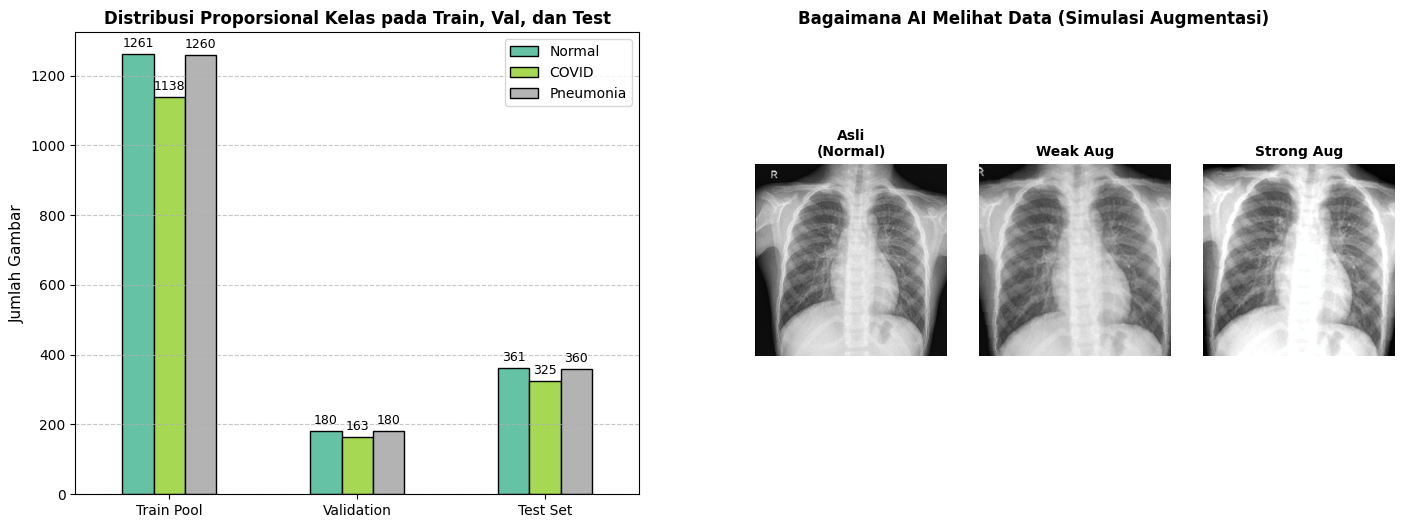


✅ FASE 3 SELESAI TOTAL: Struktur 5 Sel Data Preparation Berhasil Dieksekusi!


In [ ]:
# ==============================================================================
# FASE 3.5: DATA PREPARATION | VISUALISASI HASIL SPLITTING & EFEK AUGMENTASI
# ==============================================================================
def hitung_kelas(labels_list):
    counts = {c: 0 for c in CLASSES}
    for lbl in labels_list: counts[CLASSES[lbl]] += 1
    return counts

train_counts, val_counts, test_counts = hitung_kelas(train_labels_total), hitung_kelas(val_labels), hitung_kelas(test_labels)
tot_train, tot_val, tot_test = len(train_labels_total), len(val_labels), len(test_labels)

print("\n📋 BUKTI PEMBAGIAN DATA YANG ADIL (STRATIFIED SPLIT):")
print("-" * 85)
print(f"{'Kelas':<12} | {'Train Pool (70%)':<20} | {'Validation (10%)':<20} | {'Test Set (20%)':<20}")
print("-" * 85)
for c in CLASSES:
    str_train = f"{train_counts[c]} ({train_counts[c]/tot_train*100:.1f}%)" if tot_train > 0 else "0 (0%)"
    str_val = f"{val_counts[c]} ({val_counts[c]/tot_val*100:.1f}%)" if tot_val > 0 else "0 (0%)"
    str_test = f"{test_counts[c]} ({test_counts[c]/tot_test*100:.1f}%)" if tot_test > 0 else "0 (0%)"
    print(f"{c:<12} | {str_train:<20} | {str_val:<20} | {str_test:<20}")
print("-" * 85)

df_split = pd.DataFrame([train_counts, val_counts, test_counts], index=['Train Pool', 'Validation', 'Test Set'])
fig = plt.figure(figsize=(16, 6))

ax1 = fig.add_subplot(1, 2, 1)
df_split.plot(kind='bar', ax=ax1, colormap='Set2', edgecolor='black')
ax1.set_title('Distribusi Proporsional Kelas pada Train, Val, dan Test', fontweight='bold', fontsize=12)
ax1.set_ylabel('Jumlah Gambar', fontsize=11); ax1.tick_params(axis='x', rotation=0); ax1.grid(axis='y', linestyle='--', alpha=0.7)
for container in ax1.containers: ax1.bar_label(container, padding=3, fontsize=9)

ax2 = fig.add_subplot(1, 2, 2)
ax2.axis('off')
ax2.set_title('Bagaimana AI Melihat Data (Simulasi Augmentasi)', fontweight='bold', fontsize=12)

demo_idx = random.randint(0, len(used_paths)-1)
demo_img = Image.open(used_paths[demo_idx])
demo_label = CLASSES[used_labels[demo_idx]]

def denormalize(tensor):
    mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
    return np.clip(tensor.numpy().transpose((1, 2, 0)) * std + mean, 0, 1)

ax_orig = fig.add_axes([0.55, 0.2, 0.12, 0.6]); ax_orig.imshow(demo_img); ax_orig.set_title(f"Asli\n({demo_label})", fontsize=10, fontweight='bold'); ax_orig.axis('off')
ax_weak = fig.add_axes([0.69, 0.2, 0.12, 0.6]); ax_weak.imshow(denormalize(tf_weak(demo_img))); ax_weak.set_title("Weak Aug", fontsize=10, fontweight='bold'); ax_weak.axis('off')
ax_strong = fig.add_axes([0.83, 0.2, 0.12, 0.6]); ax_strong.imshow(denormalize(tf_strong(demo_img))); ax_strong.set_title("Strong Aug", fontsize=10, fontweight='bold'); ax_strong.axis('off')

save_visual_path = os.path.join(DIR_VISUAL, '00_data_split_visualization.png')
plt.savefig(save_visual_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✅ FASE 3 SELESAI TOTAL: Struktur 5 Sel Data Preparation Berhasil Dieksekusi!")

# FASE 4 (Data Modeling)

SEL 4.1: FUNGSI PEMBANGKIT SKENARIO (LABELED vs UNLABELED)

In [ ]:
# ==============================================================================
# FASE 4.1: MODELING | FUNGSI DISTRIBUSI LABELED & UNLABELED (SKENARIO ABLASI)
# ==============================================================================
print("⚙️ MENYIAPKAN MESIN PEMBANGKIT SKENARIO LABELED/UNLABELED...")

def siapkan_data_skenario(persen):
    rasio = persen / 100.0
    print(f"\n📦 MEMPERSIAPKAN DATA SKENARIO {persen}% LABELED...")

    # 1. Memecah Train Pool (70%) menjadi Labeled dan Unlabeled berdasarkan Rasio (5%, 10%, 20%)
    l_paths_base, u_paths_base, l_labels_base, u_labels_base = train_test_split(
        train_paths_total, train_labels_total, train_size=rasio, random_state=SEED, stratify=train_labels_total)

    l_paths_raw, l_labels_raw, u_paths_raw, u_labels_raw = [], [], list(u_paths_base), list(u_labels_base)
    kelas_count = {0: 0, 1: 0, 2: 0}

    # 2. Logika Ketimpangan Alami (Imbalanced Retention)
    for path, lbl in zip(l_paths_base, l_labels_base):
        if kelas_count[lbl] < MINIMAL_GAMBAR_PER_KELAS:
            l_paths_raw.append(path); l_labels_raw.append(lbl); kelas_count[lbl] += 1
        else:
            if random.random() <= RETENTION_RATES[lbl]:
                l_paths_raw.append(path); l_labels_raw.append(lbl)
            else:
                u_paths_raw.append(path); u_labels_raw.append(lbl)

    folder_skenario_fisik = os.path.join(DIR_SPLIT_SKENARIO, f"{persen}_persen")
    folder_csv_skenario = os.path.join(DIR_CSV, f"Skenario_{persen}_Persen")
    os.makedirs(folder_csv_skenario, exist_ok=True)

    # 3. Kopi fisik ke folder & Penyamaran Unlabeled (Memanggil fungsi Kuli Bangunan dari Fase 3)
    l_paths = copy_to_physical_folder(l_paths_raw, l_labels_raw, os.path.join(folder_skenario_fisik, "labeled"), "Data LABELED")
    u_paths = copy_to_physical_folder(u_paths_raw, u_labels_raw, os.path.join(folder_skenario_fisik, "unlabeled"), "Data UNLABELED", is_unlabeled=True)

    # 4. Mencatat Buku Registrasi Skenario ke CSV
    df_labeled = pd.DataFrame({'Path_Gambar': l_paths, 'Label_Asli': [CLASSES[lbl] for lbl in l_labels_raw], 'Status': 'LABELED'})
    df_unlabeled = pd.DataFrame({'Path_Gambar': u_paths, 'Label_Asli': [CLASSES[lbl] for lbl in u_labels_raw], 'Status': 'UNLABELED (HIDDEN)'})
    pd.concat([df_labeled, df_unlabeled]).to_csv(os.path.join(folder_csv_skenario, f'Buku_Registrasi_{persen}_Persen.csv'), index=False)

    # 5. Membungkus menjadi DataLoader (Siap masuk AI)
    batch_l = max(4, min(16, len(l_paths) // 4))
    labeled_loader = DataLoader(CXR_SSL_Dataset(l_paths, labels=l_labels_raw, transform_weak=tf_weak), batch_size=batch_l, shuffle=True, drop_last=True)
    unlabeled_loader = DataLoader(CXR_SSL_Dataset(u_paths, labels=None, transform_weak=tf_weak, transform_strong=tf_strong, is_unlabeled=True), batch_size=BATCH_SIZE_UNLABELED, shuffle=True, drop_last=True)

    return labeled_loader, unlabeled_loader, len(l_paths), len(u_paths)

print("✅ FASE 4.1 SELESAI: Fungsi Pembangkit Skenario Siap!")

⚙️ MENYIAPKAN MESIN PEMBANGKIT SKENARIO LABELED/UNLABELED...
✅ FASE 4.1 SELESAI: Fungsi Pembangkit Skenario Siap!


SEL 4.2: FUNGSI ARSITEKTUR SOFTMATCH (THE ENGINE)

In [ ]:
# ==============================================================================
# FASE 4.2: MODELING | FUNGSI TRAINING SOFTMATCH DENSENET-121 (THE ENGINE)
# ==============================================================================
print("⚙️ MENYIAPKAN MESIN ARSITEKTUR SOFTMATCH...")

def latih_model_softmatch(persen, use_ua, labeled_loader, unlabeled_loader):
    status_ua = "Dengan_UA" if use_ua else "Tanpa_UA"
    SAVE_DIR = os.path.join(DIR_TRAINING, f"Skenario_{persen}_Persen_Imbalanced_{status_ua}")
    os.makedirs(SAVE_DIR, exist_ok=True)

    # Fitur Penghemat Waktu: Jika model sudah pernah dibuat, lewati.
    if os.path.exists(os.path.join(SAVE_DIR, 'best_model.pth')):
        print(f"⏭️ Model {persen}% | {status_ua.replace('_', ' ')} sudah ada. Melompat!")
        return

    print(f"\n🚀 MEMULAI TRAINING: {persen}% LABELED | {status_ua.replace('_', ' ').upper()}")

    # 1. Pembangunan Arsitektur Model (DenseNet121)
    model = models.densenet121(pretrained=True)
    model.classifier = nn.Linear(model.classifier.in_features, NUM_CLASSES)
    model = model.to(DEVICE)

    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=TOTAL_EPOCHS)

    # 2. Variabel EMA (Exponential Moving Average) untuk SoftMatch
    mu_t = torch.tensor(1.0/NUM_CLASSES).to(DEVICE)
    var_t = torch.tensor(1.0).to(DEVICE)
    ema_p = (torch.ones(NUM_CLASSES)/NUM_CLASSES).to(DEVICE)

    best_val_acc = 0.0
    history_log = []

    # 3. Proses Belajar (Epoch Loop)
    for epoch in range(TOTAL_EPOCHS):
        model.train()
        tot_loss = 0.0
        num_batches = min(len(labeled_loader), len(unlabeled_loader))
        progress = tqdm(enumerate(zip(labeled_loader, unlabeled_loader)), total=num_batches, desc=f"Ep {epoch+1:02d}/{TOTAL_EPOCHS}", leave=False, ncols=80)

        for step, ((d_l, t_l), (d_u_w, d_u_s)) in progress:
            d_l, t_l = d_l.to(DEVICE), t_l.to(DEVICE)
            d_u_w, d_u_s = d_u_w.to(DEVICE), d_u_s.to(DEVICE)

            optimizer.zero_grad()
            loss_s = F.cross_entropy(model(d_l), t_l) # Belajar dari Guru

            # Belajar dari Murid (Pseudo-Labeling)
            with torch.no_grad():
                probs_u_w = torch.softmax(model(d_u_w), dim=1)
                max_p, pseudo_lbl = torch.max(probs_u_w, dim=1)
                batch_size_u = d_u_w.size(0)

                # Pembaruan Sejarah AI (EMA)
                mu_t = 0.999 * mu_t + 0.001 * max_p.mean()
                var_t = 0.999 * var_t + 0.001 * (batch_size_u / (batch_size_u - 1)) * max_p.var(unbiased=True)
                ema_p = 0.999 * ema_p + 0.001 * probs_u_w.mean(dim=0)

                # Uniform Alignment (Hakim Keadilan Kelas)
                if use_ua:
                    p_aligned = probs_u_w * ((torch.ones(NUM_CLASSES)/NUM_CLASSES).to(DEVICE) / (ema_p + 1e-8))
                    p_aligned = p_aligned / (p_aligned.sum(dim=1, keepdim=True) + 1e-8)
                    confidence_for_weight, _ = torch.max(p_aligned, dim=1)
                else:
                    confidence_for_weight = max_p

                # Gaussian Weighting (Dosen Toleransi Nilai)
                sigma_t = torch.sqrt(var_t + 1e-8)
                gw = torch.exp(-((confidence_for_weight - mu_t)**2) / (2 * sigma_t**2 + 1e-8))
                mask = torch.where(confidence_for_weight < mu_t, gw, torch.ones_like(gw))

            loss_u = (F.cross_entropy(model(d_u_s), pseudo_lbl, reduction='none') * mask).mean()
            loss = loss_s + loss_u
            loss.backward()
            optimizer.step()

            tot_loss += loss.item()
            progress.set_postfix({'Loss': f"{loss.item():.4f}"})

        scheduler.step()

        # 4. Evaluasi Sementara agar tidak Overfitting (Menggunakan Val Loader)
        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for d_v, t_v in val_loader:
                d_v, t_v = d_v.to(DEVICE), t_v.to(DEVICE)
                out_v = model(d_v)
                val_loss += F.cross_entropy(out_v, t_v).item()
                correct += (torch.max(out_v, 1)[1] == t_v).sum().item()
                total += t_v.size(0)

        val_acc = 100 * correct / total
        avg_val_loss = val_loss / len(val_loader)
        history_log.append({'Epoch': epoch+1, 'Train_Loss': tot_loss/num_batches, 'Val_Loss': avg_val_loss, 'Val_Acc': val_acc})

        print(f"  👉 Epoch {epoch+1:02d} | Val Acc: {val_acc:.2f}% | Val Loss: {avg_val_loss:.4f}", end="")
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(SAVE_DIR, 'best_model.pth')) # SIMPAN BOBOT
            print(" 🌟 [CHECKPOINT: BOBOT MODEL TERBAIK TERSIMPAN]")
        else: print("")

    pd.DataFrame(history_log).to_csv(os.path.join(SAVE_DIR, 'training_log.csv'), index=False)
    del model, optimizer, scheduler; torch.cuda.empty_cache(); gc.collect()

print("✅ FASE 4.2 SELESAI: Mesin Arsitektur SoftMatch telah dikonstruksi!")

⚙️ MENYIAPKAN MESIN ARSITEKTUR SOFTMATCH...
✅ FASE 4.2 SELESAI: Mesin Arsitektur SoftMatch telah dikonstruksi!


SEL 4.3: MASTER EKSEKUSI MODELING (THE ACTION)

In [ ]:
# ==============================================================================
# FASE 4.3: MODELING | EKSEKUSI UTAMA (LOOPING STUDI ABLASI)
# ==============================================================================
print("🎯 MENJALANKAN MASTER EKSEKUSI MODELING (STUDI ABLASI)...\n")

for persen in SKENARIO_RASIO:
    # 1. Bangkitkan Data Skenario (Panggil fungsi dari Sel 4.1)
    loader_guru, loader_murid, tot_l, tot_u = siapkan_data_skenario(persen)
    print(f"   -> Terbentuk: {tot_l} Data Labeled (Guru) & {tot_u} Data Unlabeled (Murid)")

    # 2. Jalankan Pelatihan AI (Panggil fungsi dari Sel 4.2)
    for use_ua in SKENARIO_UA:
        latih_model_softmatch(persen, use_ua, loader_guru, loader_murid)

print("\n🎉🎉🎉 FASE 4 (MODELING) SELESAI SEMPURNA! Semua bobot model (.pth) berhasil disimpan! 🎉🎉🎉")

🎯 MENJALANKAN MASTER EKSEKUSI MODELING (STUDI ABLASI)...


📦 MEMPERSIAPKAN DATA SKENARIO 5% LABELED...
   📋 Data LABELED: Mengkopi 102 file...


   📋 Data UNLABELED: Mengkopi 3557 file...


   -> Terbentuk: 102 Data Labeled (Guru) & 3557 Data Unlabeled (Murid)

🚀 MEMULAI TRAINING: 5% LABELED | DENGAN UA
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 185MB/s]


  👉 Epoch 01 | Val Acc: 34.42% | Val Loss: 2.1988 🌟 [CHECKPOINT: BOBOT MODEL TERBAIK TERSIMPAN]


...

  👉 Epoch 36 | Val Acc: 86.81% | Val Loss: 0.7282


  👉 Epoch 37 | Val Acc: 86.62% | Val Loss: 0.7113


  👉 Epoch 38 | Val Acc: 85.66% | Val Loss: 0.8091


  👉 Epoch 39 | Val Acc: 86.04% | Val Loss: 0.7878


  👉 Epoch 40 | Val Acc: 86.04% | Val Loss: 0.7212

🎉🎉🎉 FASE 4 (MODELING) SELESAI SEMPURNA! Semua bobot model (.pth) berhasil disimpan! 🎉🎉🎉


# FASE 5: EVALUASI PENGUJIAN & E-XPLAINABLE AI (Grad-CAM).

SEL 5.1: MASTER EVALUASI INDIVIDUAL & GRAD-CAM (THE SCIENCE)

In [ ]:
# ==============================================================================
# FASE 5.1: EVALUATION | PENGUJIAN MODEL INDIVIDUAL & VISUALISASI GRAD-CAM
# ==============================================================================
print("⚖️ MEMULAI FASE 5: EVALUASI AKHIR PADA TEST SET...\n")

# Inisialisasi ulang model kosong untuk diisi bobot (weights)
model_eval = models.densenet121(pretrained=False)
model_eval.classifier = nn.Linear(model_eval.classifier.in_features, NUM_CLASSES)
model_eval = model_eval.to(DEVICE)

for persen in SKENARIO_RASIO:
    for use_ua in SKENARIO_UA:
        status_ua = "Dengan_UA" if use_ua else "Tanpa_UA"
        nama_skenario = f"{persen}% | {status_ua.replace('_', ' ')}"
        SAVE_DIR = os.path.join(DIR_TRAINING, f"Skenario_{persen}_Persen_Imbalanced_{status_ua}")
        model_path = os.path.join(SAVE_DIR, 'best_model.pth')

        if not os.path.exists(model_path):
            print(f"⚠️ Melewati Skenario {nama_skenario} (Belum ditraining)")
            continue

        print(f"🔍 Menilai Skenario: {nama_skenario}")
        model_eval.load_state_dict(torch.load(model_path, map_location=DEVICE))
        model_eval.eval()

        all_preds, all_targets, all_probs = [], [], []

        # 1. Proses Ujian (Inference)
        with torch.no_grad():
            for d_t, t_t in test_loader:
                probs = torch.softmax(model_eval(d_t.to(DEVICE)), dim=1)
                all_preds.extend(torch.max(probs, 1)[1].cpu().numpy())
                all_targets.extend(t_t.numpy())
                all_probs.extend(probs.cpu().numpy())

        # 2. Cetak Laporan Rapor (Classification Report)
        report_str = classification_report(all_targets, all_preds, target_names=CLASSES, digits=4)
        with open(os.path.join(SAVE_DIR, 'classification_report.txt'), 'w') as f:
            f.write(report_str)

        # 3. Visualisasi Confusion Matrix
        plt.figure(figsize=(5, 4))
        sns.heatmap(confusion_matrix(all_targets, all_preds), annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
        plt.title(f'Confusion Matrix ({nama_skenario})', fontweight='bold')
        plt.ylabel('Label Asli'); plt.xlabel('Tebakan AI')
        plt.savefig(os.path.join(SAVE_DIR, 'confusion_matrix.png'), bbox_inches='tight')
        plt.close()

        # 4. Visualisasi ROC Curve
        plt.figure(figsize=(6, 4))
        y_bin = label_binarize(all_targets, classes=[0, 1, 2])
        colors = ['blue', 'red', 'green']
        for i, col in zip(range(NUM_CLASSES), colors):
            if sum(y_bin[:, i]) > 0:
                fpr, tpr, _ = roc_curve(y_bin[:, i], np.array(all_probs)[:, i])
                plt.plot(fpr, tpr, color=col, lw=2, label=f'ROC {CLASSES[i]} (AUC = {auc(fpr, tpr):0.2f})')
        plt.plot([0, 1], [0, 1], 'k--')
        plt.legend(loc="lower right"); plt.title(f'ROC Curve ({nama_skenario})', fontweight='bold')
        plt.savefig(os.path.join(SAVE_DIR, 'roc_curve.png'), bbox_inches='tight')
        plt.close()

        # 5. Visualisasi Explainable AI (Grad-CAM Medis)
        try:
            cam = GradCAM(model=model_eval, target_layers=[model_eval.features[-1]])
            d_cam, t_cam = next(iter(test_loader)) # Ambil 1 batch acak dari test set

            fig, axes = plt.subplots(1, 3, figsize=(15, 5))
            for i in range(3):
                img_tensor = d_cam[i].unsqueeze(0).to(DEVICE)
                gc_img = cam(input_tensor=img_tensor, targets=[ClassifierOutputTarget(t_cam[i].item())])[0, :]
                img_orig = np.clip(np.array([0.229, 0.224, 0.225]) * d_cam[i].cpu().numpy().transpose((1, 2, 0)) + np.array([0.485, 0.456, 0.406]), 0, 1)

                axes[i].imshow(show_cam_on_image(img_orig, gc_img, use_rgb=True))
                axes[i].set_title(f"Target Asli: {CLASSES[t_cam[i].item()]}", fontweight='bold')
                axes[i].axis('off')

            plt.suptitle(f"Grad-CAM Bukti Klinis ({nama_skenario})", fontsize=16, fontweight='bold')
            plt.savefig(os.path.join(SAVE_DIR, 'grad_cam.png'), bbox_inches='tight')
            plt.close()
        except Exception as e:
            print(f"⚠️ Grad-CAM gagal di-render untuk {nama_skenario}: {e}")

print("\n✅ FASE 5.1 SELESAI: Evaluasi Test Set, Confusion Matrix, ROC, dan Grad-CAM telah disimpan di masing-masing folder Skenario!")

⚖️ MEMULAI FASE 5: EVALUASI AKHIR PADA TEST SET...

🔍 Menilai Skenario: 5% | Dengan UA
🔍 Menilai Skenario: 5% | Tanpa UA
🔍 Menilai Skenario: 10% | Dengan UA
🔍 Menilai Skenario: 10% | Tanpa UA
🔍 Menilai Skenario: 20% | Dengan UA
🔍 Menilai Skenario: 20% | Tanpa UA

✅ FASE 5.1 SELESAI: Evaluasi Test Set, Confusion Matrix, ROC, dan Grad-CAM telah disimpan di masing-masing folder Skenario!


SEL 5.2: GRAND DASHBOARD ABLATION STUDY (THE EVIDENCE)

📊 MEMBANGUN DASHBOARD PERBANDINGAN STUDI ABLASI...



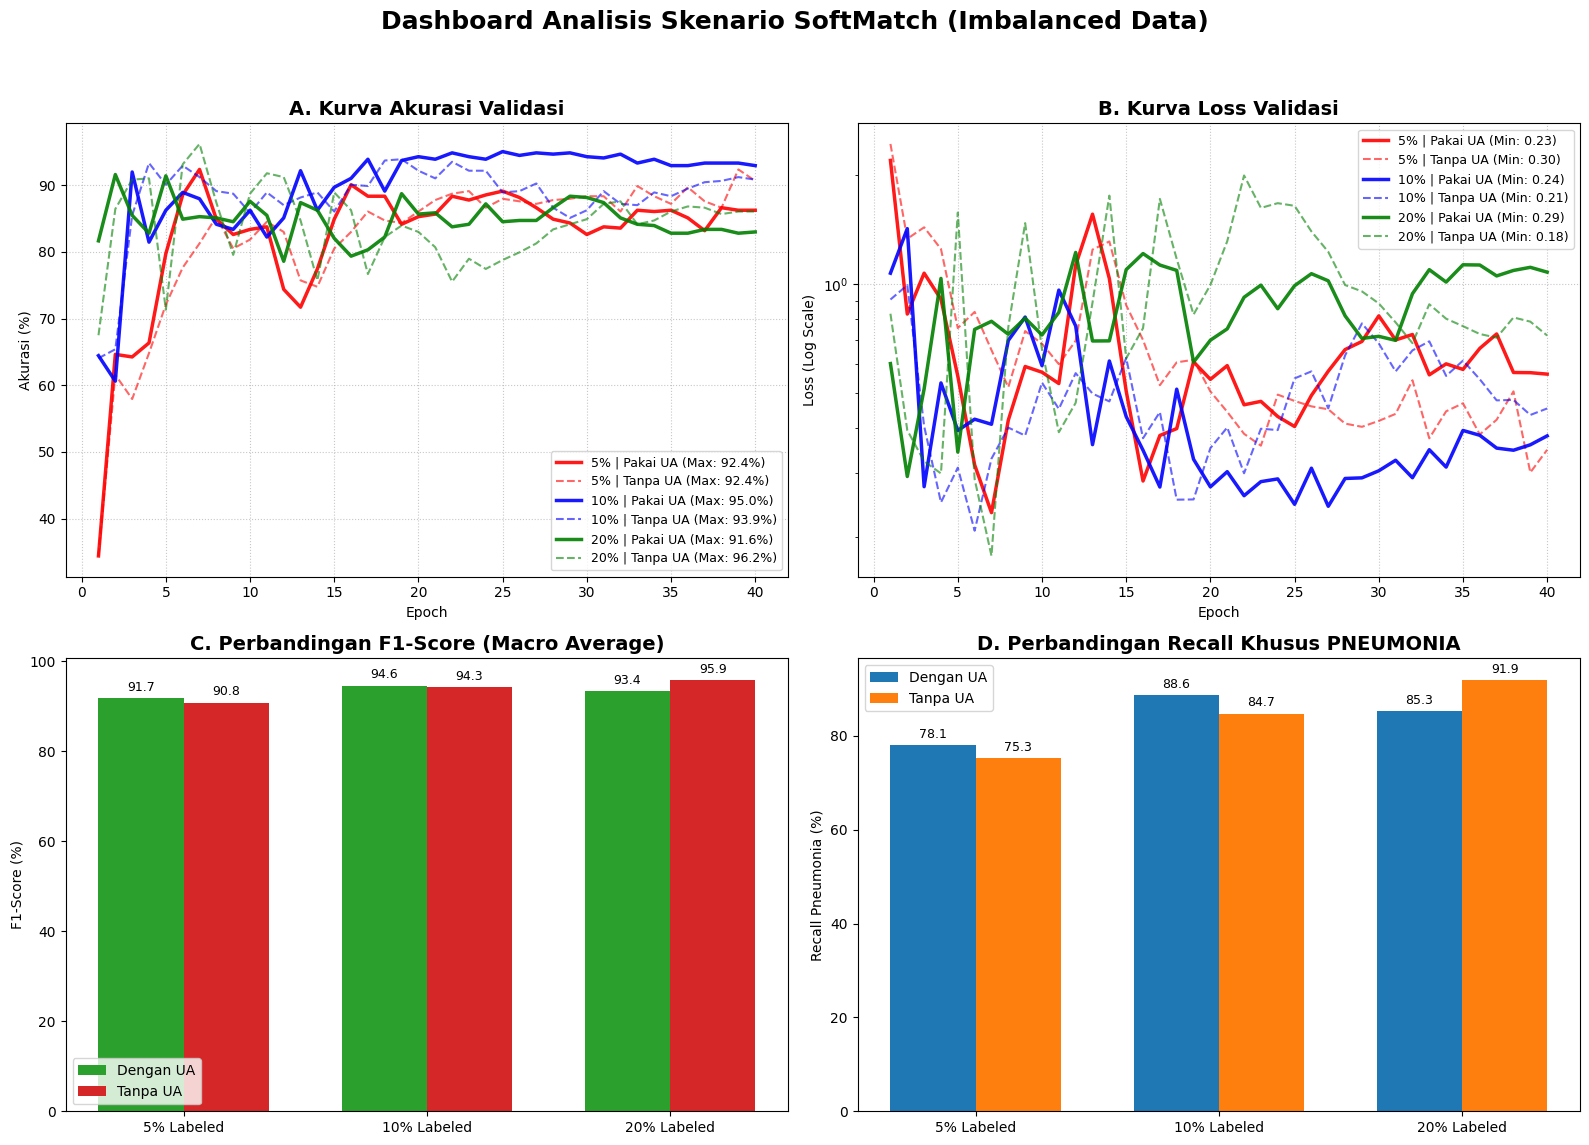


🏆 REKAPITULASI & PERINGKAT MODEL TERBAIK 🏆
 1. 20% | Tanpa UA       | F1-Score: 95.89% | Recall Pneu: 91.94%
 2. 10% | Pakai UA       | F1-Score: 94.58% | Recall Pneu: 88.61%
 3. 10% | Tanpa UA       | F1-Score: 94.31% | Recall Pneu: 84.72%
 4. 20% | Pakai UA       | F1-Score: 93.37% | Recall Pneu: 85.28%
 5. 5% | Pakai UA        | F1-Score: 91.72% | Recall Pneu: 78.06%
 6. 5% | Tanpa UA        | F1-Score: 90.82% | Recall Pneu: 75.28%


In [ ]:
# ==============================================================================
# FASE 5.2: EVALUATION | DASHBOARD PERBANDINGAN STUDI ABLASI
# ==============================================================================
print("📊 MEMBANGUN DASHBOARD PERBANDINGAN STUDI ABLASI...\n")

warna_garis = {5: 'red', 10: 'blue', 20: 'green'}
gaya_garis = {True: '-', False: '--'}

data_f1_macro = {'Dengan_UA': [], 'Tanpa_UA': []}
data_recall_pneu = {'Dengan_UA': [], 'Tanpa_UA': []}
label_bar = [f"{p}% Labeled" for p in SKENARIO_RASIO]
data_ditemukan = False

fig, axs = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Dashboard Analisis Skenario SoftMatch (Imbalanced Data)', fontsize=18, fontweight='bold', y=0.98)

rekapitulasi = []

for persen in SKENARIO_RASIO:
    for use_ua in SKENARIO_UA:
        status_ua = "Dengan_UA" if use_ua else "Tanpa_UA"
        nama_skenario = f"{persen}% | {'Pakai UA' if use_ua else 'Tanpa UA'}"
        folder_path = os.path.join(DIR_TRAINING, f"Skenario_{persen}_Persen_Imbalanced_{status_ua}")
        csv_path = os.path.join(folder_path, "training_log.csv")
        txt_path = os.path.join(folder_path, "classification_report.txt")

        best_acc = 0.0
        if os.path.exists(csv_path) and os.path.exists(txt_path):
            data_ditemukan = True
            df = pd.read_csv(csv_path)

            if not df.empty and 'Val_Acc' in df.columns:
                best_acc = df["Val_Acc"].max()
                axs[0, 0].plot(df['Epoch'], df['Val_Acc'], linestyle=gaya_garis[use_ua], color=warna_garis[persen], linewidth=2.5 if use_ua else 1.5, alpha=0.9 if use_ua else 0.6, label=f'{nama_skenario} (Max: {best_acc:.1f}%)')
                axs[0, 1].plot(df['Epoch'], df['Val_Loss'], linestyle=gaya_garis[use_ua], color=warna_garis[persen], linewidth=2.5 if use_ua else 1.5, alpha=0.9 if use_ua else 0.6, label=f'{nama_skenario} (Min: {df["Val_Loss"].min():.2f})')

            f1_macro, recall_pneu = 0.0, 0.0
            with open(txt_path, 'r') as f:
                for line in f.readlines():
                    parts = line.split()
                    if not parts: continue
                    if parts[0] == 'Pneumonia': recall_pneu = float(parts[2]) * 100
                    elif 'macro' in parts and 'avg' in parts: f1_macro = float(parts[-2]) * 100

            data_f1_macro[status_ua].append(f1_macro)
            data_recall_pneu[status_ua].append(recall_pneu)
            rekapitulasi.append({'Skenario': nama_skenario, 'Val_Acc': best_acc, 'F1_Macro': f1_macro, 'Recall_Pneumonia': recall_pneu})
        else:
            data_f1_macro[status_ua].append(0)
            data_recall_pneu[status_ua].append(0)

if data_ditemukan:
    # Setir Gaya Plot
    axs[0, 0].set_title('A. Kurva Akurasi Validasi', fontsize=14, fontweight='bold'); axs[0, 0].set_xlabel('Epoch'); axs[0, 0].set_ylabel('Akurasi (%)'); axs[0, 0].legend(loc='lower right', fontsize=9); axs[0, 0].grid(True, linestyle=':', alpha=0.7)
    axs[0, 1].set_title('B. Kurva Loss Validasi', fontsize=14, fontweight='bold'); axs[0, 1].set_xlabel('Epoch'); axs[0, 1].set_ylabel('Loss (Log Scale)'); axs[0, 1].legend(loc='upper right', fontsize=9); axs[0, 1].grid(True, linestyle=':', alpha=0.7); axs[0, 1].set_yscale('log')

    x = np.arange(len(label_bar))
    width = 0.35

    # Bar F1-Score
    axs[1, 0].bar(x - width/2, data_f1_macro['Dengan_UA'], width, label='Dengan UA', color='#2ca02c')
    axs[1, 0].bar(x + width/2, data_f1_macro['Tanpa_UA'], width, label='Tanpa UA', color='#d62728')
    axs[1, 0].set_title('C. Perbandingan F1-Score (Macro Average)', fontsize=14, fontweight='bold'); axs[1, 0].set_ylabel('F1-Score (%)'); axs[1, 0].set_xticks(x); axs[1, 0].set_xticklabels(label_bar); axs[1, 0].legend()
    for container in axs[1, 0].containers: axs[1, 0].bar_label(container, fmt='%.1f', padding=3, fontsize=9)

    # Bar Recall Pneumonia
    axs[1, 1].bar(x - width/2, data_recall_pneu['Dengan_UA'], width, label='Dengan UA', color='#1f77b4')
    axs[1, 1].bar(x + width/2, data_recall_pneu['Tanpa_UA'], width, label='Tanpa UA', color='#ff7f0e')
    axs[1, 1].set_title('D. Perbandingan Recall Khusus PNEUMONIA', fontsize=14, fontweight='bold'); axs[1, 1].set_ylabel('Recall Pneumonia (%)'); axs[1, 1].set_xticks(x); axs[1, 1].set_xticklabels(label_bar); axs[1, 1].legend()
    for container in axs[1, 1].containers: axs[1, 1].bar_label(container, fmt='%.1f', padding=3, fontsize=9)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    save_path = os.path.join(DIR_VISUAL, 'Grafik_Ablation_Dashboard_Lengkap.png')
    plt.savefig(save_path, dpi=300)
    plt.show()

    df_rekap = pd.DataFrame(rekapitulasi)
    print("\n" + "="*60 + "\n🏆 REKAPITULASI & PERINGKAT MODEL TERBAIK 🏆\n" + "="*60)
    for index, row in df_rekap.sort_values(by='F1_Macro', ascending=False).reset_index(drop=True).iterrows():
        print(f" {index+1}. {row['Skenario']:<20} | F1-Score: {row['F1_Macro']:.2f}% | Recall Pneu: {row['Recall_Pneumonia']:.2f}%")
else:
    print("⚠️ KESIMPULAN: Data Model Belum Lengkap! Pastikan Master Eksekusi Modeling (Fase 4.3) telah dijalankan.")

🟢 SEL 5.3: ANALISIS OVERFITTING (TRAIN LOSS vs VALIDATION LOSS)

📉 MENGGAMBAR KURVA PEMBELAJARAN (ANALISIS OVERFITTING)...



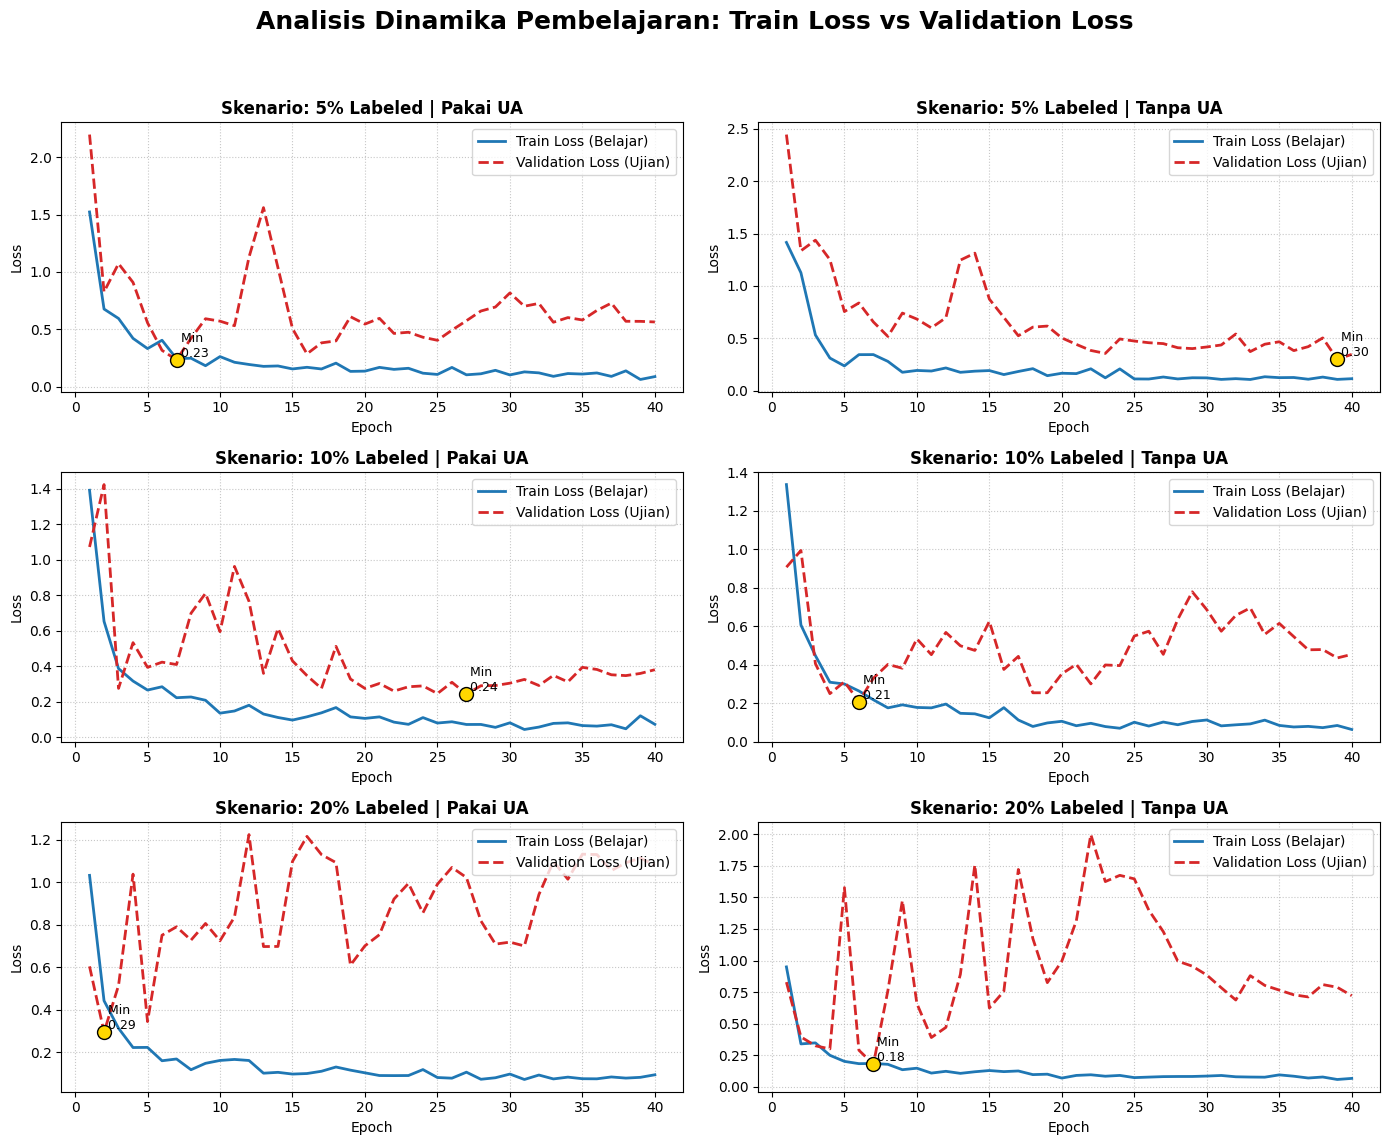

✅ FASE 5.3 SELESAI: Grafik perbandingan Loss berhasil disimpan di: ./HASIL_PENELITIAN/BUKTI_FISIK_4_KATALOG_VISUAL/Grafik_Analisis_Overfitting.png


In [ ]:
# ==============================================================================
# FASE 5.3: EVALUATION | ANALISIS OVERFITTING (TRAIN vs VALIDATION LOSS)
# ==============================================================================
print("📉 MENGGAMBAR KURVA PEMBELAJARAN (ANALISIS OVERFITTING)...\n")

# Membuat kanvas grid sesuai jumlah skenario (Misal: 3 Baris x 2 Kolom)
fig, axes = plt.subplots(len(SKENARIO_RASIO), len(SKENARIO_UA), figsize=(14, 4 * len(SKENARIO_RASIO)))
fig.suptitle('Analisis Dinamika Pembelajaran: Train Loss vs Validation Loss', fontsize=18, fontweight='bold', y=0.98)

# Jika hanya ada 1 baris/kolom, pastikan axes tetap berbentuk 2D array untuk indexing
if len(SKENARIO_RASIO) == 1: axes = np.expand_dims(axes, axis=0)
if len(SKENARIO_UA) == 1: axes = np.expand_dims(axes, axis=1)

data_tersedia = False

for i, persen in enumerate(SKENARIO_RASIO):
    for j, use_ua in enumerate(SKENARIO_UA):
        status_ua = "Dengan_UA" if use_ua else "Tanpa_UA"
        nama_skenario = f"{persen}% Labeled | {'Pakai UA' if use_ua else 'Tanpa UA'}"

        csv_path = os.path.join(DIR_TRAINING, f"Skenario_{persen}_Persen_Imbalanced_{status_ua}", "training_log.csv")
        ax = axes[i, j]

        if os.path.exists(csv_path):
            data_tersedia = True
            df = pd.read_csv(csv_path)

            # Menggambar dua garis yang saling berbalapan (Train vs Val)
            ax.plot(df['Epoch'], df['Train_Loss'], label='Train Loss (Belajar)', color='#1f77b4', linewidth=2)
            ax.plot(df['Epoch'], df['Val_Loss'], label='Validation Loss (Ujian)', color='#d62728', linewidth=2, linestyle='--')

            ax.set_title(f"Skenario: {nama_skenario}", fontsize=12, fontweight='bold')
            ax.set_xlabel('Epoch', fontsize=10)
            ax.set_ylabel('Loss', fontsize=10)
            ax.legend(loc='upper right')
            ax.grid(True, linestyle=':', alpha=0.7)

            # Menandai titik loss terendah (Best Model)
            best_epoch = df['Val_Loss'].idxmin()
            best_val_loss = df['Val_Loss'].min()
            ax.scatter(best_epoch + 1, best_val_loss, color='gold', s=100, zorder=5, edgecolor='black', label='Best Model')
            ax.text(best_epoch + 1, best_val_loss, f' Min\n {best_val_loss:.2f}', fontsize=9, va='bottom')
        else:
            ax.set_title(f"Skenario {nama_skenario}\n(Data Belum Tersedia)", color='gray')
            ax.axis('off')

if data_tersedia:
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    save_path = os.path.join(DIR_VISUAL, 'Grafik_Analisis_Overfitting.png')
    plt.savefig(save_path, dpi=300)
    plt.show()
    print(f"✅ FASE 5.3 SELESAI: Grafik perbandingan Loss berhasil disimpan di: {save_path}")
else:
    plt.close()
    print("⚠️ KESIMPULAN: Data Model Belum Lengkap! Pastikan Master Eksekusi Modeling telah dijalankan.")

# SEL 6: DEPLOYMENT & LIVE TESTING (LIVE DEMO SIDANG)

🏥 === SISTEM DIAGNOSIS CXR OTOMATIS (SOFTMATCH + UA) === 🏥

🔍 Memanggil otak AI untuk Skenario: 10% Labeled | Dengan UA...
🏆 MODEL DITEMUKAN! Sedang memuat ingatan ke dalam sistem...

👇 SILAKAN UPLOAD 1 GAMBAR RONTGEN (CXR) PASIEN BARU 👇


Saving hidden_img_00050.png to hidden_img_00050.png

🔄 Menganalisis gambar: hidden_img_00050.png...


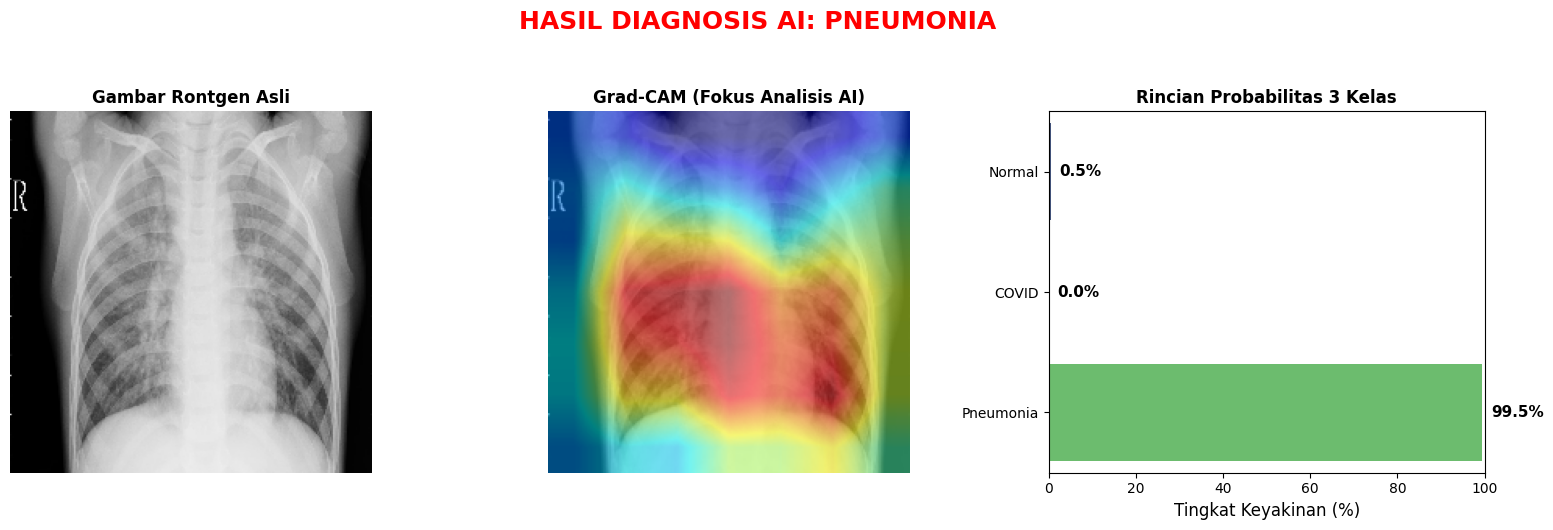

📝 CATATAN KLINIS:
Sistem sangat yakin (99.5%) pasien ini mengidap indikasi Pneumonia.


In [ ]:
# ==============================================================================
# FASE FINAL: DEPLOYMENT INTERAKTIF & GRAD-CAM (DEMO SIDANG FINAL)
# ==============================================================================
import os
import io
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from google.colab import files

try:
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image
except ImportError:
    print("⚠️ Menginstal Grad-CAM...")
    os.system('pip install grad-cam -q')
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image

print("🏥 === SISTEM DIAGNOSIS CXR OTOMATIS (SOFTMATCH + UA) === 🏥\n")

# ---------------------------------------------------------
# 🎛️ PANEL KENDALI (UBAH ANGKA INI SESUAI REQUEST DOSEN)
# ---------------------------------------------------------
PILIHAN_PERSEN = 10   # Pilihan valid: 5, 10, atau 20
STATUS_UA = "Dengan_UA" # Dikunci mutlak hanya untuk model UA

print(f"🔍 Memanggil otak AI untuk Skenario: {PILIHAN_PERSEN}% Labeled | {STATUS_UA.replace('_', ' ')}...")
folder_path = os.path.join(DIR_TRAINING, f"Skenario_{PILIHAN_PERSEN}_Persen_Imbalanced_{STATUS_UA}")
best_model_path = os.path.join(folder_path, "best_model.pth")

if not os.path.exists(best_model_path):
    print(f"❌ ERROR: File model (.pth) tidak ditemukan di {best_model_path}!")
    print("👉 Solusi: Pastikan Anda sudah menjalankan Fase 4 atau mengekstrak ZIP dari Google Drive.")
else:
    print(f"🏆 MODEL DITEMUKAN! Sedang memuat ingatan ke dalam sistem...")

    # 1. Membangkitkan Otak AI
    ai_doctor = models.densenet121(pretrained=False)
    ai_doctor.classifier = nn.Linear(ai_doctor.classifier.in_features, NUM_CLASSES)
    ai_doctor.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
    ai_doctor = ai_doctor.to(DEVICE)
    ai_doctor.eval()

    # Resep Preprocessing (Wajib sama persis dengan Test Set)
    norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    tf_deploy = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(), norm
    ])

    # ---------------------------------------------------------
    # 2. PROSES UPLOAD & PREDIKSI
    # ---------------------------------------------------------
    print("\n👇 SILAKAN UPLOAD 1 GAMBAR RONTGEN (CXR) PASIEN BARU 👇")
    uploaded = files.upload()

    for fn in uploaded.keys():
        print(f"\n🔄 Menganalisis gambar: {fn}...")

        # Buka Gambar
        img_pil = Image.open(io.BytesIO(uploaded[fn])).convert('RGB')
        img_tensor = tf_deploy(img_pil).unsqueeze(0).to(DEVICE)

        # Prediksi AI
        with torch.no_grad():
            output = ai_doctor(img_tensor)
            probs = F.softmax(output, dim=1)[0].cpu().numpy() * 100

        pred_idx = np.argmax(probs)
        pred_class = CLASSES[pred_idx] # Menggunakan array CLASSES dari Fase 1
        pred_conf = probs[pred_idx]

        # Logika "Penyakit Lain / Ragu-ragu" (Safety Mechanism)
        THRESHOLD_YAKIN = 60.0
        if pred_conf < THRESHOLD_YAKIN:
            diagnosis_final = "⚠️ UNCERTAIN (RAGU-RAGU)"
            pesan_dokter = "Sistem mendeteksi pola yang tidak dominan. Ada kemungkinan ini adalah penyakit paru-paru lain (TBC/Kanker/dll) atau kualitas CXR kurang baik. Mohon periksa ulang secara manual."
            warna_teks = 'orange'
        else:
            diagnosis_final = pred_class.upper()
            pesan_dokter = f"Sistem sangat yakin ({pred_conf:.1f}%) pasien ini mengidap indikasi {pred_class}."
            warna_teks = 'green' if pred_class == 'Normal' else 'red'

        # ---------------------------------------------------------
        # 3. BUAT GRAD-CAM UNTUK GAMBAR UPLOAD
        # ---------------------------------------------------------
        try:
            cam = GradCAM(model=ai_doctor, target_layers=[ai_doctor.features[-1]])
            gc_img = cam(input_tensor=img_tensor, targets=[ClassifierOutputTarget(pred_idx)])[0, :]

            # Denormalisasi untuk visualisasi
            img_show = np.clip(np.array([0.229, 0.224, 0.225]) * img_tensor[0].cpu().numpy().transpose((1, 2, 0)) + np.array([0.485, 0.456, 0.406]), 0, 1)
            cam_result = show_cam_on_image(img_show, gc_img, use_rgb=True)
        except Exception as e:
            print(f"⚠️ Peringatan: Gagal memproses Grad-CAM. Menampilkan gambar asli saja.")
            cam_result = np.array(img_pil) # Fallback jika error

        # ---------------------------------------------------------
        # 4. TAMPILKAN HASIL (DASHBOARD 3 PANEL)
        # ---------------------------------------------------------
        fig, axes = plt.subplots(1, 3, figsize=(16, 5))
        fig.suptitle(f"HASIL DIAGNOSIS AI: {diagnosis_final}", fontsize=18, fontweight='bold', color=warna_teks, y=1.05)

        # Panel 1: Gambar Asli
        axes[0].imshow(img_pil)
        axes[0].set_title("Gambar Rontgen Asli", fontweight='bold')
        axes[0].axis('off')

        # Panel 2: Grad-CAM
        axes[1].imshow(cam_result)
        axes[1].set_title("Grad-CAM (Fokus Analisis AI)", fontweight='bold')
        axes[1].axis('off')

        # Panel 3: Bar Chart Horizontal (Probabilitas 3 Kelas)
        sns.barplot(x=probs, y=CLASSES, ax=axes[2], palette='viridis')
        axes[2].set_xlim(0, 100)
        axes[2].set_title("Rincian Probabilitas 3 Kelas", fontweight='bold')
        axes[2].set_xlabel("Tingkat Keyakinan (%)", fontsize=12)

        # Tulis angka di batang grafik
        for i, p in enumerate(probs):
            axes[2].text(p + 2, i, f"{p:.1f}%", va='center', fontweight='bold', fontsize=11)

        plt.tight_layout()
        plt.show()

        print("="*75)
        print(f"📝 CATATAN KLINIS:\n{pesan_dokter}")
        print("="*75)

# SEL 7: BACKUP BUKTI FISIK KE GOOGLE DRIVE (SAVE DATA)

In [ ]:
# ==============================================================================
# FASE 7: BACKUP & PENYELAMATAN BUKTI FISIK KE GOOGLE DRIVE
# ==============================================================================
import shutil

print("🗄️ MEMULAI PROSES BACKUP BUKTI PENELITIAN KE GOOGLE DRIVE...\n")

# 1. Tentukan Nama File ZIP dan Lokasi Tujuannya
# Kita simpan di folder yang sama dengan folder "dataset" Anda
DRIVE_TARGET_DIR = os.path.dirname(DATASET_PATH)
NAMA_FILE_ZIP = "BACKUP_HASIL_PENELITIAN_SOFTMATCH"

lokasi_zip_lokal = f"./{NAMA_FILE_ZIP}" # Disimpan sementara di Colab
lokasi_zip_drive = os.path.join(DRIVE_TARGET_DIR, f"{NAMA_FILE_ZIP}.zip")

print(f"⏳ Sedang mengompres folder {BASE_EVIDENCE_DIR} menjadi .zip (Mohon tunggu)...")

# 2. Proses Zipping
shutil.make_archive(lokasi_zip_lokal, 'zip', BASE_EVIDENCE_DIR)
print("✅ Kompresi berhasil!")

# 3. Pindahkan (Copy) File ZIP ke Google Drive
print(f"🚀 Sedang mengirim file {NAMA_FILE_ZIP}.zip ke Google Drive Anda...")
shutil.copy2(f"{lokasi_zip_lokal}.zip", lokasi_zip_drive)

# Mengecek ukuran file sebagai validasi
ukuran_mb = os.path.getsize(lokasi_zip_drive) / (1024 * 1024)

print("━" * 70)
print("🎉🎉🎉 SELAMAT! SEMUA BUKTI PENELITIAN AMAN DI GOOGLE DRIVE 🎉🎉🎉")
print(f"📂 Lokasi di Drive : {lokasi_zip_drive}")
print(f"⚖️ Ukuran File     : {ukuran_mb:.2f} MB")
print("━" * 70)
print("Anda sekarang bisa menutup Google Colab tanpa takut kehilangan data model, grafik, maupun CSV.")

🗄️ MEMULAI PROSES BACKUP BUKTI PENELITIAN KE GOOGLE DRIVE...

⏳ Sedang mengompres folder ./HASIL_PENELITIAN menjadi .zip (Mohon tunggu)...
✅ Kompresi berhasil!
🚀 Sedang mengirim file BACKUP_HASIL_PENELITIAN_SOFTMATCH.zip ke Google Drive Anda...
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🎉🎉🎉 SELAMAT! SEMUA BUKTI PENELITIAN AMAN DI GOOGLE DRIVE 🎉🎉🎉
📂 Lokasi di Drive : /content/drive/MyDrive/0.TUGAS AKHIR (TA)/Project hasil/BACKUP_HASIL_PENELITIAN_SOFTMATCH.zip
⚖️ Ukuran File     : 1017.11 MB
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Anda sekarang bisa menutup Google Colab tanpa takut kehilangan data model, grafik, maupun CSV.
